# Projet Final — Analyse de Données
## Dataset : Sleep Health and Lifestyle

## **Problématique**
**Les habitudes de vie (stress, activité physique, IMC) influencent-elles la qualité et la durée du sommeil ?**

### **Description du dataset**
Le dataset contient **374 observations** et **13 variables** de types mixtes (numériques et catégorielles).  
Il décrit des informations sur des individus : âge, genre, profession, durée du sommeil, qualité du sommeil, niveau de stress, activité physique, tension artérielle, catégorie IMC et trouble du sommeil.

## Étape 2 — Chargement & Exploration initiale


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px

In [2]:
# Chargement du dataset
data =pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

In [3]:
# Aperçu des premières lignes
data.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [4]:
# afficher rapidement les dernières lignes
data.tail()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
369,370,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,Female,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
373,374,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


In [5]:
# Dimension du dataset : nombre de lignes et colonnes
print(data.shape)

(374, 13)


In [6]:
# Types de données et informations générales
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB
None


In [7]:
# Statistiques descriptives globales
print(data.describe())

        Person ID         Age  Sleep Duration  Quality of Sleep  \
count  374.000000  374.000000      374.000000        374.000000   
mean   187.500000   42.184492        7.132086          7.312834   
std    108.108742    8.673133        0.795657          1.196956   
min      1.000000   27.000000        5.800000          4.000000   
25%     94.250000   35.250000        6.400000          6.000000   
50%    187.500000   43.000000        7.200000          7.000000   
75%    280.750000   50.000000        7.800000          8.000000   
max    374.000000   59.000000        8.500000          9.000000   

       Physical Activity Level  Stress Level  Heart Rate   Daily Steps  
count               374.000000    374.000000  374.000000    374.000000  
mean                 59.171123      5.385027   70.165775   6816.844920  
std                  20.830804      1.774526    4.135676   1617.915679  
min                  30.000000      3.000000   65.000000   3000.000000  
25%                  45.000000 

In [8]:
#  Afficher le type de chaque colonne
data.dtypes

,0
Person ID,int64
Gender,object
Age,int64
Occupation,object
Sleep Duration,float64
Quality of Sleep,int64
Physical Activity Level,int64
Stress Level,int64
BMI Category,object
Blood Pressure,object


In [9]:
# Détection des valeurs manquantes
missing_data = data.isnull().sum()
print("Valeurs manquantes :")
missing_data

Valeurs manquantes :


,0
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


In [10]:
# Détection des doublons
duplicates = data.duplicated()
print("Nombre de doublons :", duplicates.sum())

Nombre de doublons : 0


In [11]:
# Afficher les valeurs uniques de la colonne Sleep Disorder
unique_sleep_disorder = data["Sleep Disorder"].unique()
print("Valeurs uniques de Sleep Disorder :")
unique_sleep_disorder

Valeurs uniques de Sleep Disorder :


array([nan, 'Sleep Apnea', 'Insomnia'], dtype=object)

In [12]:
# Afficher les valeurs uniques de la colonne BMI Category

unique_bmi = data["BMI Category"].unique()
print("Valeurs uniques de BMI Category :")
unique_bmi

Valeurs uniques de BMI Category :


array(['Overweight', 'Normal', 'Obese', 'Normal Weight'], dtype=object)

## Étape 3 — Nettoyage & Préparation des données

### 3.1 Traitement des valeurs manquantes
La colonne `Sleep Disorder` contient des NaN pour les personnes **sans trouble du sommeil**.  
On remplace ces NaN par `"None"` car ce n'est pas une erreur — ces personnes n'ont simplement aucun trouble.

In [13]:
# Remplacement des valeurs manquantes par "None"
data["Sleep Disorder"] = data["Sleep Disorder"].fillna("None")

In [14]:

# Vérification : plus aucune valeur manquante
missing_data = data.isnull().sum()
print("Valeurs manquantes après nettoyage :")
missing_data

Valeurs manquantes après nettoyage :


,0
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


### 3.2 Harmonisation des valeurs de BMI Category
`"Normal"` et `"Normal Weight"` représentent la même catégorie.  
On unifie les deux labels avec `.replace()` pour éviter des doublons dans les analyses.

In [15]:
# Remplacement de "Normal Weight" par "Normal"
data["BMI Category"] = data["BMI Category"].replace("Normal Weight", "Normal")

In [16]:
# Vérification des valeurs uniques après harmonisation
data["BMI Category"].unique()

array(['Overweight', 'Normal', 'Obese'], dtype=object)

### 3.3 Séparation de la colonne Blood Pressure
La colonne `Blood Pressure` contient deux informations dans le format `"120/80"`.  
On sépare en `Systolic BP` et `Diastolic BP` pour pouvoir les analyser séparément.

In [17]:
# Séparation de Blood Pressure en deux colonnes numériques
data[["Systolic BP", "Diastolic BP"]] = data["Blood Pressure"].str.split("/", expand=True).astype(int)
# Suppression de la colonne d'origine devenue redondante
data = data.drop(columns=["Blood Pressure"])

In [18]:
# Vérification
print(data[["Systolic BP", "Diastolic BP"]].head())
print(data[["Systolic BP", "Diastolic BP"]].isnull().sum())

   Systolic BP  Diastolic BP
0          126            83
1          125            80
2          125            80
3          140            90
4          140            90
Systolic BP     0
Diastolic BP    0
dtype: int64


In [19]:
# Afficher les premières lignes pour vérifier les nouvelles colonnes
data.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic BP,Diastolic BP
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,None,126,83
1,2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
2,3,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


### 3.4 Suppression de la colonne Person ID
La colonne `Person ID` est un identifiant sans valeur analytique.  
On la supprime pour alléger le dataset.

In [20]:
# Suppression de la colonne Person ID
data = data.drop(columns=["Person ID"])

In [21]:
# Vérification des colonnes restantes
data.columns

Index(['Gender', 'Age', 'Occupation', 'Sleep Duration', 'Quality of Sleep',
       'Physical Activity Level', 'Stress Level', 'BMI Category', 'Heart Rate',
       'Daily Steps', 'Sleep Disorder', 'Systolic BP', 'Diastolic BP'],
      dtype='object')

### 3.5 Suppression des doublons
On supprime les lignes dupliquées et on réinitialise les index pour avoir un dataset propre.

In [22]:
print("Nombre de doublons :", data.duplicated().sum())

Nombre de doublons : 242


In [23]:
# Suppression des doublons
data.drop_duplicates(inplace=True)
data = data.reset_index(drop=True)

In [24]:
print("Nombre de doublons restants :", data.duplicated().sum())
print("Taille finale du dataset :", data.shape)

Nombre de doublons restants : 0
Taille finale du dataset : (132, 13)


## Étape 4 — Analyse Descriptive & Statistique

In [25]:
# Statistiques descriptives après nettoyage
round(data.describe(), 2)

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic BP,Diastolic BP
count,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00
mean,41.13,7.08,7.15,58.39,5.54,71.20,6637.88,128.36,84.54
std,8.81,0.78,1.27,20.47,1.74,4.87,1766.29,7.83,6.05
min,27.00,5.80,4.00,30.00,3.00,65.00,3000.00,115.00,75.00
25%,33.75,6.40,6.00,44.25,4.00,68.00,5000.00,120.75,80.00
50%,41.00,7.15,7.00,60.00,6.00,70.00,7000.00,130.00,85.00
75%,49.00,7.72,8.00,75.00,7.00,74.00,8000.00,135.00,88.50
max,59.00,8.50,9.00,90.00,8.00,86.00,10000.00,142.00,95.00


In [26]:
# Répartition par genre
gender_count = data["Gender"].value_counts()
print("Répartition par genre :")
print(gender_count)

Répartition par genre :
Gender
Male      67
Female    65
Name: count, dtype: int64


In [27]:
# Répartition par catégorie BMI
bmi_count = data["BMI Category"].value_counts()
print("Répartition par BMI :")
print(bmi_count)

Répartition par BMI :
BMI Category
Normal        73
Overweight    52
Obese          7
Name: count, dtype: int64


In [28]:
# Répartition par trouble du sommeil
sleep_disorder_count = data["Sleep Disorder"].value_counts()
print("Répartition des troubles du sommeil :")
print(sleep_disorder_count)

Répartition des troubles du sommeil :
Sleep Disorder
None           73
Sleep Apnea    30
Insomnia       29
Name: count, dtype: int64


In [29]:
# Moyennes des variables principales
print("Qualité moyenne du sommeil :", round(data["Quality of Sleep"].mean(), 2))
print("Durée moyenne du sommeil :", round(data["Sleep Duration"].mean(), 2))
print("Niveau moyen de stress :", round(data["Stress Level"].mean(), 2))

Qualité moyenne du sommeil : 7.15
Durée moyenne du sommeil : 7.08
Niveau moyen de stress : 5.54


In [30]:
# Qualité moyenne du sommeil par catégorie BMI
quality_by_bmi = data.groupby("BMI Category")["Quality of Sleep"].mean().sort_values()
print("Qualité du sommeil par BMI :")
print(round(quality_by_bmi, 2))

Qualité du sommeil par BMI :
BMI Category
Obese         6.29
Overweight    6.77
Normal        7.51
Name: Quality of Sleep, dtype: float64


In [31]:
# Niveau de stress moyen par profession
stress_by_occupation = data.groupby("Occupation")["Stress Level"].mean().sort_values(ascending=False)
print("Stress moyen par profession :")
print(round(stress_by_occupation, 2))

Stress moyen par profession :
Occupation
Sales Representative    8.00
Salesperson             7.00
Scientist               7.00
Doctor                  6.54
Software Engineer       6.33
Nurse                   5.76
Lawyer                  5.13
Manager                 5.00
Teacher                 5.00
Accountant              4.82
Engineer                4.23
Name: Stress Level, dtype: float64


In [32]:
# Table croisée entre BMI Category et Sleep Disorder
cross_tab_bmi_sleep = pd.crosstab(data["BMI Category"], data["Sleep Disorder"])
cross_tab_bmi_sleep

Sleep Disorder,Insomnia,None,Sleep Apnea
BMI Category,,,
Normal,8,58,7
Obese,3,0,4
Overweight,18,15,19


In [33]:
# Utilisation de loc
# Afficher les lignes de 0 à 3 et certaines colonnes

data.loc[0:3, ["Gender", "Age", "Occupation", "Sleep Duration", "Quality of Sleep"]]


,Gender,Age,Occupation,Sleep Duration,Quality of Sleep
0,Male,27,Software Engineer,6.1,6
1,Male,28,Doctor,6.2,6
2,Male,28,Sales Representative,5.9,4
3,Male,28,Software Engineer,5.9,4


In [34]:
# Utilisation de iloc
# Afficher les 4 premières lignes et les 6 premières colonnes

data.iloc[0:4, 0:6]

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level
0,Male,27,Software Engineer,6.1,6,42
1,Male,28,Doctor,6.2,6,60
2,Male,28,Sales Representative,5.9,4,30
3,Male,28,Software Engineer,5.9,4,30


In [35]:
# Matrice de corrélation
num_variables = data.select_dtypes(include=["number"]).columns
correl = round(data[num_variables].corr(), 3)
correl

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic BP,Diastolic BP
Age,1.000,0.348,0.488,0.255,-0.404,-0.270,0.146,0.531,0.537
Sleep Duration,0.348,1.000,0.869,0.269,-0.828,-0.509,0.019,-0.222,-0.205
Quality of Sleep,0.488,0.869,1.000,0.290,-0.884,-0.660,0.148,-0.180,-0.156
Physical Activity Level,0.255,0.269,0.290,1.000,-0.106,-0.015,0.721,0.208,0.328
Stress Level,-0.404,-0.828,-0.884,-0.106,1.000,0.592,0.113,0.151,0.140
Heart Rate,-0.270,-0.509,-0.660,-0.015,0.592,1.000,-0.297,0.376,0.325
Daily Steps,0.146,0.019,0.148,0.721,0.113,-0.297,1.000,-0.023,0.125
Systolic BP,0.531,-0.222,-0.180,0.208,0.151,0.376,-0.023,1.000,0.971
Diastolic BP,0.537,-0.205,-0.156,0.328,0.140,0.325,0.125,0.971,1.000


## Étape 5 — Visualisations

### Graphique 1 — Boxplot : Stress et qualité du sommeil

Ce graphe montre clairement que **plus le niveau de stress augmente, plus la qualité du sommeil diminue**.  
La médiane de qualité chute de 8 (stress faible) à environ 4 (stress élevé).

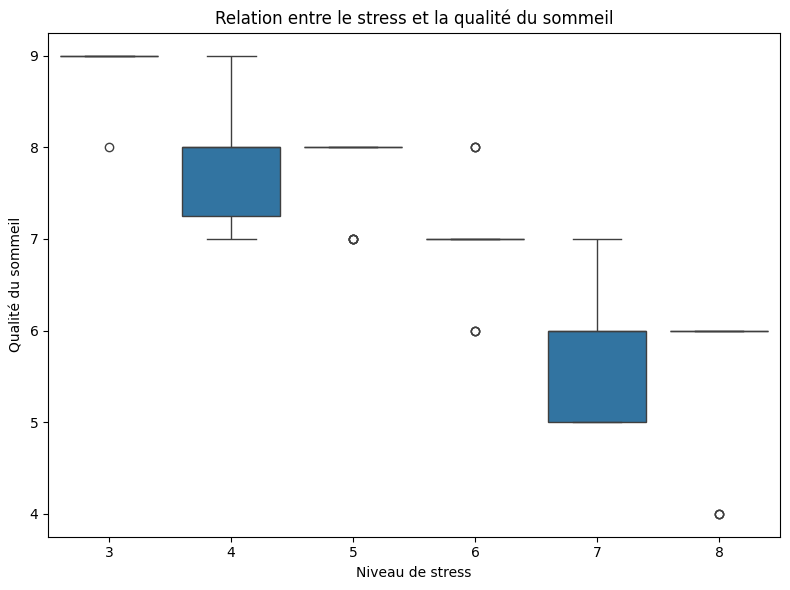

In [36]:
plt.figure(figsize=(8, 6))

sns.boxplot(x="Stress Level", y="Quality of Sleep", data=data)

plt.title("Relation entre le stress et la qualité du sommeil")
plt.xlabel("Niveau de stress")
plt.ylabel("Qualité du sommeil")
plt.tight_layout()

plt.show()

### Interprétation

On observe que lorsque le niveau de stress augmente, la qualité du sommeil diminue progressivement.

Les personnes ayant un stress élevé présentent une qualité de sommeil plus faible et plus dispersée.

Cela montre qu’il existe une relation négative entre le stress et la qualité du sommeil.

### Graphique 2 — Heatmap : Matrice de corrélation

La heatmap montre les corrélations entre toutes les variables numériques.  
Les principales observations :
- `Sleep Duration` et `Quality of Sleep` : **corrélation positive forte** (+0.88)
- `Stress Level` et `Quality of Sleep` : **corrélation négative forte** (-0.90)
- `Stress Level` et `Sleep Duration` : **corrélation négative** (-0.81)

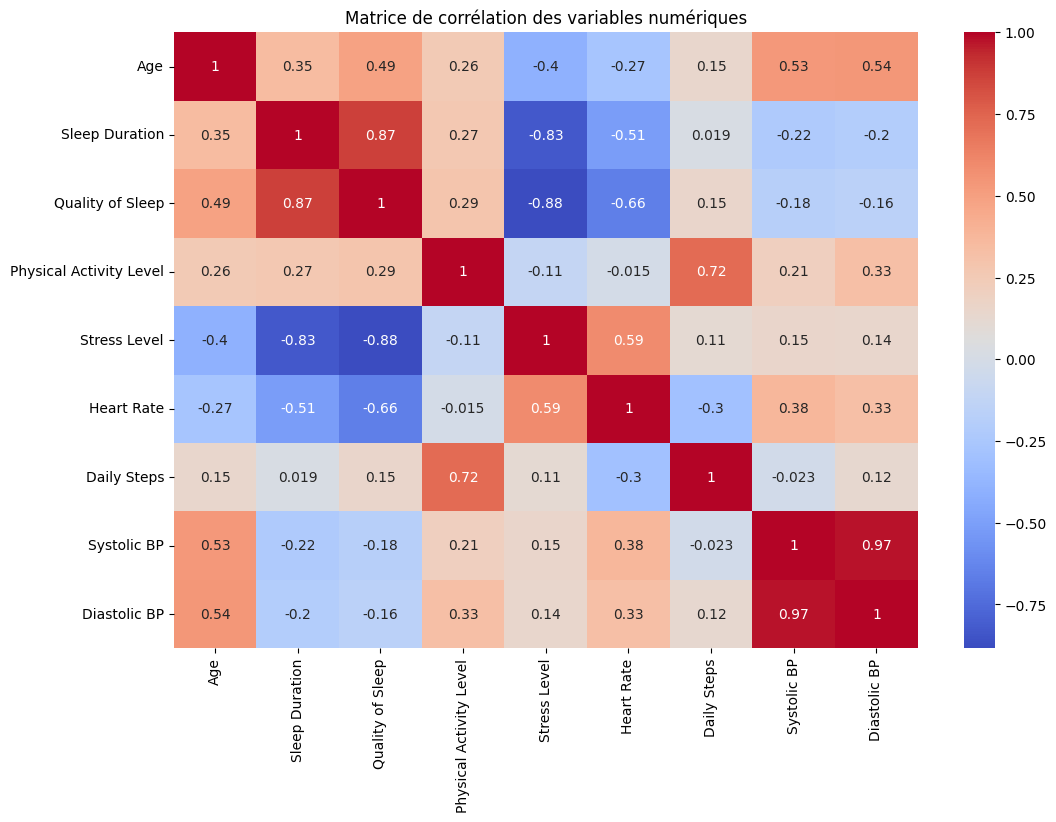

In [37]:
plt.figure(figsize=(12, 8))

sns.heatmap(correl, annot=True, cmap="coolwarm")

plt.title("Matrice de corrélation des variables numériques")

plt.show()

### Interprétation

La heatmap montre une forte corrélation négative entre le stress et la qualité du sommeil.

Elle montre également une corrélation positive entre la durée du sommeil et sa qualité.

Ces relations confirment que le stress influence négativement le sommeil tandis qu’une bonne durée de sommeil améliore sa qualité.

### Graphique 3 — Countplot : BMI et troubles du sommeil

Ce graphique croise deux variables catégorielles pour comparer les troubles du sommeil selon la catégorie IMC.  
On observe que les personnes en **surpoids (Overweight)** sont les plus touchées par l'apnée du sommeil,  
tandis que les personnes **obèses** présentent plus d'insomnie.

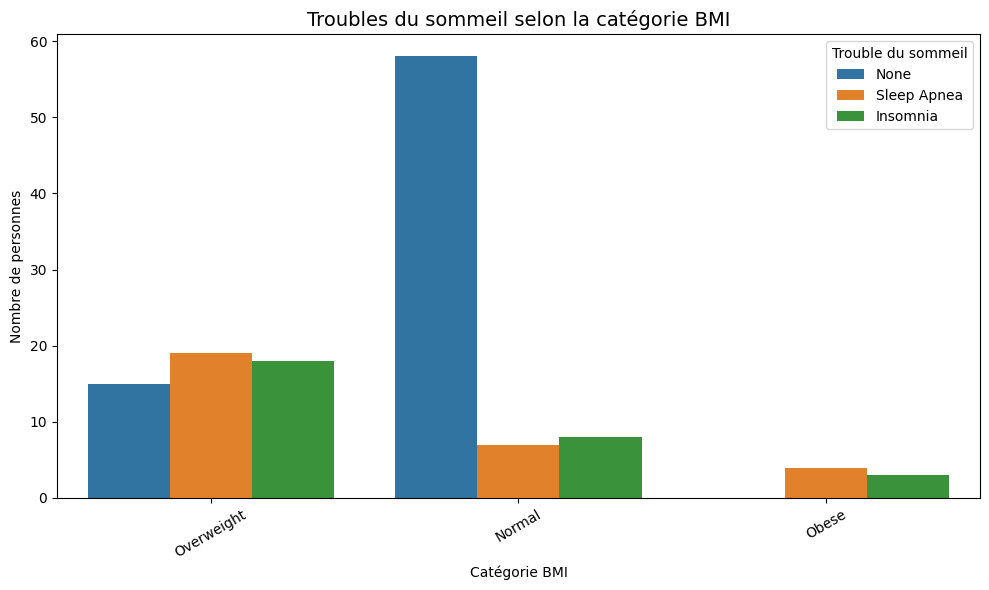

In [38]:
plt.figure(figsize=(10, 6))

sns.countplot(x="BMI Category", hue="Sleep Disorder", data=data)

plt.title("Troubles du sommeil selon la catégorie BMI", fontsize=14)
plt.xlabel("Catégorie BMI")
plt.ylabel("Nombre de personnes")
plt.xticks(rotation=30)
plt.legend(title="Trouble du sommeil")

plt.tight_layout()
plt.show()

### Interprétation

Les personnes ayant un BMI normal présentent moins de troubles du sommeil.

En revanche, les personnes en surpoids ou obèses semblent davantage touchées par l’apnée du sommeil et l’insomnie.

Cela suggère que le poids peut avoir un impact sur la qualité du sommeil et les troubles associés.

### Graphique 4 — Bar interactif : Qualité moyenne du sommeil par profession *(Plotly)*

Ce graphique interactif montre la qualité moyenne du sommeil par profession.  


In [39]:
occupation_quality = data.groupby("Occupation")["Quality of Sleep"].mean().round(2).reset_index()

fig = px.bar(
    occupation_quality,
    x="Occupation",
    y="Quality of Sleep",
    title="Qualité moyenne du sommeil par profession",
    text="Quality of Sleep"
)

fig.update_traces(textposition="outside")

fig.show()

### Interprétation

Le graphique montre que la qualité du sommeil varie selon les professions.

Certaines professions présentent une meilleure qualité de sommeil, probablement grâce à un niveau de stress plus faible et un meilleur équilibre de vie.

D’autres professions affichent une qualité de sommeil plus faible, ce qui peut être lié à :
- la charge de travail,
- le stress professionnel,
- les horaires irréguliers.

Cela suggère que l’environnement professionnel influence directement la qualité du sommeil.

## Étape 6 — Interprétation & Conclusions

### Synthèse des principaux résultats

- Le **stress** est le facteur le plus lié à la mauvaise qualité du sommeil (corrélation de -0.90)
- La **durée du sommeil** est fortement liée à sa qualité (corrélation de +0.88)
- Les personnes en **surpoids** sont plus exposées à l'apnée du sommeil
- Certaines **professions** (vendeurs, scientifiques) présentent un stress moyen plus élevé et une qualité de sommeil plus faible

---

### Réponse à la problématique

**Les habitudes de vie influencent effectivement la qualité et la durée du sommeil.**  
Le stress et l'IMC sont les facteurs les plus déterminants.  
Dormir plus longtemps est associé à une meilleure qualité de sommeil.

---

### Limites de l'analyse

- Le dataset contient seulement **374 observations**, ce qui limite la généralisation
- Les données peuvent être **déclaratives** (auto-évaluées)
- Des variables importantes manquent : alimentation, utilisation des écrans, horaires de travail
- Les corrélations observées ne prouvent **pas une causalité**

---

### Recommandations

- Réduire le stress par des techniques de relaxation ou de méditation
- Pratiquer une activité physique régulière
- Surveiller l'IMC et la tension artérielle
- Consulter un spécialiste en cas de troubles du sommeil fréquents
- Compléter l'étude avec davantage de données médicales et comportementales